# Challenge 2: Grover's Algorithm for Key Search under Noise

Author: Abdullah Al Omar Galib (Ahkatlio)

| Item | Details |
|:--|:--|
| Difficulty | Medium |
| Required knowledge | Quantum circuits, multi-controlled gates, amplitude amplification, density matrices and noise channels, binomial statistics |
| Required packages | `qiskit` 2.6, `qiskit-aer` 0.18, `numpy`, `matplotlib` (see `requirements.txt`) |
| Total available points | 100 |
| Objective | Implement Grover search for a hidden key, then measure how depolarizing and bit-flip noise limit the number of useful iterations |
| Expected deliverables | Completed functions for Tasks GRV-T1 to GRV-T9, the experiments in Section 9, and written answers GRV-Q1 to GRV-Q4 |

## How to use this notebook

* Run the cells from top to bottom. The official grader re-executes the whole notebook in a clean kernel with a fresh seed.
* Cells whose first line is `# Provided Code: Do Not Modify` are organizer-provided. Do not edit, delete, duplicate or reorder them; such changes are detected automatically and treated under the integrity rules in Section 11.
* Cells whose first line is `# Participant Code: Task ...` are yours. Replace `# Your code here` and the `raise NotImplementedError(...)` line. Keep function names and parameter lists exactly as given.
* You may add cells for exploration and helper functions.
* Hints are collapsible and progressively more detailed. Using them does not affect your score.
* Public checks only test basic properties. The grader uses hidden keys, other search-space sizes and other noise levels.

## 1. Problem overview

A brute-force attacker who wants to recover an $n$-bit secret key must, classically, test about half of the $N = 2^{n}$ candidates on average. Grover's algorithm finds a marked item among $N$ candidates with about $\frac{\pi}{4}\sqrt{N}$ queries to an oracle that recognizes the marked item, a quadratic speed-up that is provably optimal for unstructured search.

The speed-up assumes a perfect quantum computer. On real hardware every gate is imperfect, and Grover circuits are deep: each iteration contains two multi-controlled gates whose decomposition into one- and two-qubit gates grows quickly with $n$. In this challenge you will implement Grover search for a hidden key, verify the ideal success probability, and then study how two noise models (depolarizing and bit-flip) erode the success probability, change the best number of iterations, and determine when the quantum search stops beating a fair classical baseline.

## 2. Learning objectives

1. Build a phase oracle for a given bit string and the Grover diffusion operator without ancilla qubits.
2. Explain amplitude amplification as a rotation in a two-dimensional subspace and derive $P_r = \sin^2\big((2r+1)\theta\big)$.
3. Define noise models in Qiskit Aer and relate them to the basis gates of a transpiled circuit.
4. Design reproducible numerical experiments with finite shot budgets, and quantify their statistical uncertainty.
5. Compare quantum and classical search with a consistent definition of resources.

## 3. Prerequisites

* Hadamard, Pauli and controlled gates; multi-controlled gates in Qiskit (`ZGate().control(k, annotated=False)`, `mcx`).
* Qiskit's bit ordering: in a bit string such as `"0110"`, the **last** character refers to qubit 0.
* Density matrices and quantum channels, in particular $\rho \mapsto (1-\lambda)\rho + \lambda\, I/d$.
* The binomial distribution and the standard error $\sqrt{P(1-P)/n}$ of an estimated probability.

## 4. Scientific background

### 4.1 Unstructured search

The oracle model hides the key $k \in \{0,1\}^{n}$ inside a black box that, given a candidate $x$, answers whether $x = k$. Any classical algorithm needs $\Theta(N)$ queries to find $k$ with constant probability. Grover's algorithm needs $O(\sqrt{N})$ queries, and Bennett, Bernstein, Brassard and Vazirani showed that no quantum algorithm can do better for this problem.

### 4.2 Amplitude amplification

Starting from the uniform superposition $\lvert s \rangle = H^{\otimes n}\lvert 0 \rangle^{\otimes n}$, each Grover iteration applies a phase oracle, which flips the sign of the marked state, and the diffusion operator, which reflects all amplitudes about their mean. The two reflections compose to a rotation that moves amplitude from the unmarked states to the marked state.

### 4.3 Noise in deep circuits

The gate count of a Grover iteration is dominated by the multi-controlled gates. Without ancillas, an $n$-qubit multi-controlled $Z$ needs a number of CNOT gates that grows rapidly with $n$ (Barenco et al., 1995). Each noisy gate mixes a little of the ideal state with other states. After many gates the register approaches the maximally mixed state, for which the probability of measuring the key is $1/N$, exactly the probability of a blind classical guess.

## 5. Mathematical formulation

### 5.1 The two-dimensional picture

Let $N = 2^{n}$ and let $M$ be the number of marked states ($M = 1$ in this challenge). Define $\theta$ by
$$
\sin^2\theta = \frac{M}{N}.
$$
With $\lvert w \rangle$ the marked state and $\lvert w^{\perp} \rangle$ the normalized uniform superposition of the unmarked states,
$$
\lvert s \rangle = \sin\theta\, \lvert w \rangle + \cos\theta\, \lvert w^{\perp} \rangle .
$$
The oracle $O = I - 2\lvert w \rangle\langle w \rvert$ and the diffuser $D = 2\lvert s \rangle\langle s \rvert - I$ are reflections, and $G = D\,O$ is a rotation by $2\theta$ in the plane spanned by $\lvert w \rangle$ and $\lvert w^{\perp} \rangle$. After $r$ iterations
$$
G^{r}\lvert s \rangle = \sin\big((2r+1)\theta\big)\lvert w \rangle + \cos\big((2r+1)\theta\big)\lvert w^{\perp} \rangle,
\qquad
P_r = \sin^2\big((2r+1)\theta\big).
$$
The ideal optimum $r^{*}$ is the smallest non-negative integer that maximizes $P_r$; it is close to $\frac{\pi}{4\theta} - \frac{1}{2}$.

### 5.2 Bit-ordering convention

Secret keys are bit strings in Qiskit's convention: the last character is qubit 0. The key `"0110"` therefore marks the basis state with qubit 0 in $\lvert 0 \rangle$, qubits 1 and 2 in $\lvert 1 \rangle$ and qubit 3 in $\lvert 0 \rangle$, which is the state whose measurement gives the counts key `"0110"`.

### 5.3 Noise models

Every circuit is run through the official transpilation pipeline (`ph.official_transpile`: basis gates `rz`, `sx`, `x`, `cx`, all-to-all connectivity, optimization level 1, fixed seed). Noise is attached to the basis gates.

* **Depolarizing model $\mathcal{D}(p)$:** a two-qubit depolarizing channel with parameter $p$ after every `cx`, a single-qubit depolarizing channel with parameter $p/10$ after every `sx` and `x`, and no error on `rz`. Here a $d$-dimensional depolarizing channel with parameter $\lambda$ is $\rho \mapsto (1-\lambda)\rho + \lambda\, I/d$, as in `qiskit_aer.noise.depolarizing_error(lam, num_qubits)`.
* **Bit-flip model $\mathcal{B}(q)$:** after every `sx` and `x`, the target qubit suffers an $X$ error with probability $q$; after every `cx`, each of its two qubits independently suffers an $X$ error with probability $q$; `rz` is error-free.

### 5.4 Classical baseline

A blind classical guess succeeds with probability
$$
P_{\mathrm{classical}} = \frac{1}{N}.
$$
For a fair comparison with $r$ Grover iterations, which use $r$ oracle queries, give the classical attacker the same number of queries: test $k = r$ distinct random candidates and, if the key was not among them, guess uniformly among the remaining $N - k$. The success probability is
$$
P_{\mathrm{classical}}(k) = \frac{k}{N} + \left(1 - \frac{k}{N}\right)\frac{1}{N-k} = \frac{k+1}{N}, \qquad k < N,
$$
and $1$ for $k \ge N - 1$. Both sides then use $r$ queries and output one candidate key.

### 5.5 Shot budget

Probabilities are estimated from a finite number of shots. An estimate $\hat{P}$ from $m$ shots has standard error $\sqrt{P(1-P)/m}$. In Task GRV-T9 the total number of shots is fixed, and every shot you use through `ph.run_counts` is counted.

## 6. Environment checks

In [18]:
# Provided Code: Do Not Modify
import sys
from pathlib import Path

_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "public_helpers.py").exists()), None)
if _ROOT is None:
    raise FileNotFoundError("Could not find src/public_helpers.py. Start Jupyter from inside the hackathon folder.")
if str(_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(_ROOT / "src"))

import math

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit.library import ZGate
from qiskit.quantum_info import Operator, Statevector
from qiskit_aer.noise import NoiseModel, depolarizing_error, pauli_error

import public_helpers as ph
from public_helpers import BASIS_GATES, SHOT_LEDGER, count_two_qubit_gates, official_transpile, run_counts

ph.check_environment()

public_helpers version: 1.0.0
  qiskit      2.6.1      ok
  qiskit_aer  0.18.2     ok
  numpy       2.4.6      ok
  scipy       1.17.1     ok
  matplotlib  3.11.2     ok


{'qiskit': '2.6.1',
 'qiskit_aer': '0.18.2',
 'numpy': '2.4.6',
 'scipy': '1.17.1',
 'matplotlib': '3.11.2'}

## 7. Provided starter code

* `run_counts(circuit, shots, seed, noise_model)` transpiles the circuit with the official settings, runs it on `AerSimulator` and returns a counts dictionary. Every call adds its shots to `SHOT_LEDGER`.
* `official_transpile(circuit)` and `count_two_qubit_gates(circuit)` give the official compiled circuit and its two-qubit gate count.
* `SEED` is the session seed. The grader changes it between runs.
* `EXPERIMENT_SHOTS` is the maximum number of shots per configuration in the experiments of Section 9.

In [19]:
# Provided Code: Do Not Modify
SEED = ph.get_seed()
EXPERIMENT_SHOTS = 4000
DEMO_KEY = "0110"

print(f"Session seed: {SEED}")
print(f"Demonstration key: {DEMO_KEY} (qubit 0 is the last character)")

Session seed: 2026
Demonstration key: 0110 (qubit 0 is the last character)


## 8. Participant implementation tasks

The grader calls each function with hidden keys of 2 to 6 bits, other iteration counts and other noise strengths. Implement the general behavior described in each specification.

### Task GRV-T1: Phase oracle (15 points)

Implement `build_oracle(secret_key)`.

* **Input:** `secret_key`, a string of `"0"` and `"1"` characters of length $n$ with $2 \le n \le 8$, in Qiskit bit order (Section 5.2).
* **Returns:** a `QuantumCircuit` on exactly $n$ qubits, without classical bits, ancillas or measurements, that implements $O\lvert x \rangle = (-1)^{[x = k]}\lvert x \rangle$ up to a global phase.
* **Edge cases:** raise `ValueError` if the key is not a string, has length outside $[2, 8]$, or contains characters other than `"0"` and `"1"`.
* **Evaluation:** the grader compares the unitary of your circuit with the ideal oracle for hidden keys.

In [20]:
# Participant Code: Task GRV-T1
def _validate_key(secret_key):
    if not isinstance(secret_key, str):
        raise ValueError("secret_key must be a string")
    if not 2 <= len(secret_key) <= 8:
        raise ValueError("secret_key length must be between 2 and 8")
    if any(ch not in "01" for ch in secret_key):
        raise ValueError("secret_key may only contain '0' and '1'")


def build_oracle(secret_key: str) -> QuantumCircuit:
    """Phase oracle that multiplies the basis state |secret_key> by -1."""
    _validate_key(secret_key)
    n = len(secret_key)
    circuit = QuantumCircuit(n)
    zero_qubits = [n - 1 - pos for pos, ch in enumerate(secret_key) if ch == "0"]  # last char = qubit 0
    for q in zero_qubits:
        circuit.x(q)
    circuit.append(ZGate().control(n - 1, annotated=False), list(range(n)))
    for q in zero_qubits:
        circuit.x(q)
    return circuit

#### Hints for Task GRV-T1

Open the hints one at a time. Each hint reveals more than the previous one.

<details>
<summary>Reveal Hint 1 (Conceptual direction)</summary>

It is easy to flip the phase of one particular basis state, $\lvert 11\ldots1 \rangle$. Map the key onto that state, flip its phase, and map it back.

</details>

<details>
<summary>Reveal Hint 2 (Mathematical guidance)</summary>

A multi-controlled $Z$ gate acting on all $n$ qubits multiplies $\lvert 1\ldots1 \rangle$ by $-1$ and leaves every other basis state unchanged. Conjugating it with $X$ gates on the qubits where the key has a $0$ moves the phase flip to $\lvert k \rangle$.

</details>

<details>
<summary>Reveal Hint 3 (Implementation guidance)</summary>

Use `ZGate().control(n - 1, annotated=False)` appended to all qubits, or `circuit.h(t); circuit.mcx(controls, t); circuit.h(t)`. Remember that `secret_key[n - 1 - q]` is the bit of qubit `q`.

</details>

In [21]:
# Provided Code: Do Not Modify
def _public_check_t1():
    oracle = build_oracle(DEMO_KEY)
    assert isinstance(oracle, QuantumCircuit) and oracle.num_qubits == len(DEMO_KEY), "use exactly n qubits"
    assert oracle.num_clbits == 0, "the oracle must not contain classical bits"
    matrix = Operator(oracle).data
    diagonal = np.ones(2 ** len(DEMO_KEY))
    diagonal[int(DEMO_KEY, 2)] = -1
    phase = matrix[0, 0] / diagonal[0]
    assert np.allclose(matrix, phase * np.diag(diagonal), atol=1e-8), "wrong oracle unitary"

ph.run_public_check("GRV-T1", _public_check_t1)

[GRV-T1] passed


True

### Task GRV-T2: Diffusion operator (10 points)

Implement `build_diffuser(n_qubits)`.

* **Input:** an integer $2 \le n \le 8$; raise `ValueError` otherwise.
* **Returns:** a `QuantumCircuit` on $n$ qubits (no ancillas, no classical bits) implementing $D = 2\lvert s \rangle\langle s \rvert - I$ up to a global phase.
* **Evaluation:** unitary comparison for several values of $n$.

In [22]:
# Participant Code: Task GRV-T2
def build_diffuser(n_qubits: int) -> QuantumCircuit:
    """Diffusion operator 2|s><s| - I on n_qubits qubits (up to a global phase)."""
    if isinstance(n_qubits, bool) or not isinstance(n_qubits, (int, np.integer)) or not 2 <= n_qubits <= 8:
        raise ValueError("n_qubits must be an integer between 2 and 8")
    n = int(n_qubits)
    circuit = QuantumCircuit(n)
    circuit.h(range(n))
    circuit.x(range(n))
    circuit.append(ZGate().control(n - 1, annotated=False), list(range(n)))
    circuit.x(range(n))
    circuit.h(range(n))
    return circuit

#### Hints for Task GRV-T2

Open the hints one at a time. Each hint reveals more than the previous one.

<details>
<summary>Reveal Hint 1 (Conceptual direction)</summary>

The diffuser is a reflection about $\lvert s \rangle$. A reflection about $\lvert 0\ldots0 \rangle$ is easy to build, and $H^{\otimes n}$ maps $\lvert 0\ldots0 \rangle$ to $\lvert s \rangle$.

</details>

<details>
<summary>Reveal Hint 2 (Mathematical guidance)</summary>

$H^{\otimes n}\,(2\lvert 0 \rangle\langle 0 \rvert - I)\,H^{\otimes n} = 2\lvert s \rangle\langle s \rvert - I$, and $2\lvert 0 \rangle\langle 0 \rvert - I = -(I - 2\lvert 0 \rangle\langle 0 \rvert)$, so a phase flip of $\lvert 0\ldots0 \rangle$ is enough up to a global phase.

</details>

<details>
<summary>Reveal Hint 3 (Implementation guidance)</summary>

Surround a multi-controlled $Z$ on all qubits with layers of single-qubit gates that map $\lvert s \rangle$ to $\lvert 1\ldots1 \rangle$ before it and back afterwards. The phase-flip helper you wrote for GRV-T1 can be reused.

</details>

In [23]:
# Provided Code: Do Not Modify
def _public_check_t2():
    n = 3
    matrix = Operator(build_diffuser(n)).data
    s = np.ones(2 ** n) / np.sqrt(2 ** n)
    target = 2 * np.outer(s, s) - np.eye(2 ** n)
    phase = matrix[0, 0] / target[0, 0]
    assert np.allclose(matrix, phase * target, atol=1e-8), "wrong diffuser unitary"

ph.run_public_check("GRV-T2", _public_check_t2)

[GRV-T2] passed


True

### Task GRV-T3: Complete Grover circuit (15 points)

Implement `build_grover_circuit(secret_key, n_iterations)`.

* **Inputs:** a key as in GRV-T1 and a non-negative integer number of iterations $r$ (raise `ValueError` for negative or non-integer values).
* **Returns:** a `QuantumCircuit` with $n$ qubits and $n$ classical bits that prepares $\lvert s \rangle$, applies $r$ Grover iterations (oracle followed by diffuser), and measures qubit $i$ into classical bit $i$ for every $i$.
* **Evaluation:** for hidden keys and iteration counts the grader computes the ideal success probability of your circuit exactly and compares it with $\sin^2((2r+1)\theta)$.

In [24]:
# Participant Code: Task GRV-T3
def build_grover_circuit(secret_key: str, n_iterations: int) -> QuantumCircuit:
    """Grover search circuit with n_iterations iterations and final measurement."""
    _validate_key(secret_key)
    if isinstance(n_iterations, bool) or not isinstance(n_iterations, (int, np.integer)) or n_iterations < 0:
        raise ValueError("n_iterations must be a non-negative integer")
    n = len(secret_key)
    oracle, diffuser = build_oracle(secret_key), build_diffuser(n)
    circuit = QuantumCircuit(n, n)
    circuit.h(range(n))
    for _ in range(int(n_iterations)):
        circuit.compose(oracle, inplace=True)
        circuit.compose(diffuser, inplace=True)
    circuit.measure(range(n), range(n))
    return circuit

#### Hints for Task GRV-T3

Open the hints one at a time. Each hint reveals more than the previous one.

<details>
<summary>Reveal Hint 1 (Conceptual direction)</summary>

The algorithm is: uniform superposition, then repeat (oracle, diffuser), then measure all qubits.

</details>

<details>
<summary>Reveal Hint 2 (Mathematical guidance)</summary>

For $r = 0$ the circuit only prepares $\lvert s \rangle$ and the success probability is $1/N$. With $n = 2$ and $r = 1$ the success probability is exactly 1, which is a convenient test.

</details>

<details>
<summary>Reveal Hint 3 (Implementation guidance)</summary>

Create `QuantumCircuit(n, n)`, apply `h` to all qubits, use `circuit.compose(oracle, inplace=True)` and `circuit.compose(diffuser, inplace=True)` in a loop, and finish with `circuit.measure(range(n), range(n))`.

</details>

In [25]:
# Provided Code: Do Not Modify
def _public_check_t3():
    circuit = build_grover_circuit("101", 2)
    assert circuit.num_qubits == 3 and circuit.num_clbits == 3, "use n qubits and n classical bits"
    state = Statevector(circuit.remove_final_measurements(inplace=False))
    probability = abs(state.data[int("101", 2)]) ** 2
    theta = math.asin(math.sqrt(1 / 8))
    assert abs(probability - math.sin(5 * theta) ** 2) < 1e-8, f"success probability {probability:.4f} is wrong"

ph.run_public_check("GRV-T3", _public_check_t3)

[GRV-T3] passed


True

### Task GRV-T4: Ideal theory (8 points) and Task GRV-T5: Classical baseline (4 points)

Implement three functions.

1. `ideal_success_probability(n_qubits, n_iterations) -> float` returns $P_r = \sin^2((2r+1)\theta)$ with $\sin^2\theta = 1/2^{n}$.
2. `optimal_iterations(n_qubits) -> int` returns the **smallest** non-negative integer $r$ that maximizes $P_r$ (compare probabilities rounded to 12 decimal places so that exact ties are detected).
3. `classical_success_probability(n_qubits, n_queries) -> float` returns the query-matched classical success probability of Section 5.4; raise `ValueError` for a negative number of queries.

**Evaluation:** exact comparison (tolerance $10^{-9}$) for hidden arguments with $2 \le n \le 10$.

In [26]:
# Participant Code: Task GRV-T4
def ideal_success_probability(n_qubits: int, n_iterations: int) -> float:
    """P_r = sin^2((2r + 1) theta) for one marked state among 2**n_qubits."""
    theta = math.asin(math.sqrt(1.0 / 2 ** n_qubits))
    return float(math.sin((2 * n_iterations + 1) * theta) ** 2)


def optimal_iterations(n_qubits: int) -> int:
    """Smallest r >= 0 that maximizes the ideal success probability."""
    theta = math.asin(math.sqrt(1.0 / 2 ** n_qubits))
    r_max = math.ceil(math.pi / (4 * theta)) + 2
    probs = [round(ideal_success_probability(n_qubits, r), 12) for r in range(r_max + 1)]
    return int(probs.index(max(probs)))   # index() returns the first (smallest) maximizer


def classical_success_probability(n_qubits: int, n_queries: int) -> float:
    """Success probability of the best classical strategy with n_queries queries."""
    if n_queries < 0:
        raise ValueError("n_queries must be non-negative")
    size = 2 ** n_qubits
    if n_queries >= size - 1:
        return 1.0
    return float((n_queries + 1) / size)

#### Hints for Task GRV-T4

Open the hints one at a time. Each hint reveals more than the previous one.

<details>
<summary>Reveal Hint 1 (Conceptual direction)</summary>

$P_r$ is periodic in $r$, so the first maximum is the one you want. The classical strategy gains one candidate per query plus a final guess.

</details>

<details>
<summary>Reveal Hint 2 (Mathematical guidance)</summary>

The first maximum is near $\pi/(4\theta) - 1/2$, so it is enough to evaluate $P_r$ for $r = 0, 1, \ldots, \lfloor \pi/(4\theta) \rfloor + 1$. For $n = 2$ you should find $r^{*} = 1$ with $P_{1} = 1$.

</details>

<details>
<summary>Reveal Hint 3 (Implementation guidance)</summary>

Use `math.asin(math.sqrt(1 / 2**n))`, a list comprehension over candidate values of $r$, and `np.argmax` on the rounded list. For the classical function use `min(1.0, (k + 1) / N)`.

</details>

In [27]:
# Provided Code: Do Not Modify
def _public_check_t4():
    assert abs(ideal_success_probability(2, 1) - 1.0) < 1e-12, "P_1 must be 1 for n = 2"
    assert abs(ideal_success_probability(3, 0) - 1 / 8) < 1e-12, "P_0 must be 1/N"
    assert optimal_iterations(2) == 1, "r* must be 1 for n = 2"
    assert abs(classical_success_probability(3, 0) - 1 / 8) < 1e-12, "zero queries give 1/N"

ph.run_public_check("GRV-T4/T5", _public_check_t4)

[GRV-T4/T5] passed


True

### Task GRV-T6: Depolarizing noise model (8 points) and Task GRV-T7: Bit-flip noise model (8 points)

Implement `build_depolarizing_noise_model(p)` and `build_bitflip_noise_model(q)` exactly as specified in Section 5.3.

* **Returns:** a `qiskit_aer.noise.NoiseModel` whose basis gates are `rz`, `sx`, `x` and `cx`.
* **Edge cases:** raise `ValueError` if the parameter is outside $[0, 1]$. A parameter of $0$ must give a model that leaves every circuit unchanged.
* **Evaluation:** the grader simulates reference circuits with your model and with the official model and compares the resulting density matrices.

In [28]:
# Participant Code: Task GRV-T6/T7
def _check_probability(value, name):
    if isinstance(value, bool) or not isinstance(value, (int, float, np.integer, np.floating)) \
            or math.isnan(value) or not 0.0 <= value <= 1.0:
        raise ValueError(f"{name} must be a number in [0, 1]")
    return float(value)


def build_depolarizing_noise_model(p: float) -> NoiseModel:
    """Depolarizing model D(p): p on cx, p/10 on sx and x, no error on rz."""
    p = _check_probability(p, "p")
    model = NoiseModel(basis_gates=["rz", "sx", "x", "cx"])
    model.add_all_qubit_quantum_error(depolarizing_error(p, 2), ["cx"])
    model.add_all_qubit_quantum_error(depolarizing_error(p / 10, 1), ["sx", "x"])
    return model


def build_bitflip_noise_model(q: float) -> NoiseModel:
    """Bit-flip model B(q): X errors with probability q on every qubit a gate acts on."""
    q = _check_probability(q, "q")
    flip = pauli_error([("X", q), ("I", 1 - q)])
    model = NoiseModel(basis_gates=["rz", "sx", "x", "cx"])
    model.add_all_qubit_quantum_error(flip, ["sx", "x"])
    model.add_all_qubit_quantum_error(flip.tensor(flip), ["cx"])   # independent flips on both qubits
    return model

#### Hints for Task GRV-T6/T7

Open the hints one at a time. Each hint reveals more than the previous one.

<details>
<summary>Reveal Hint 1 (Conceptual direction)</summary>

A noise model in Qiskit Aer attaches a quantum error to gate names. Errors are applied after the gate, to the same qubits.

</details>

<details>
<summary>Reveal Hint 2 (Mathematical guidance)</summary>

For a two-qubit gate, independent bit flips on both qubits form the product channel $\mathcal{E}_q \otimes \mathcal{E}_q$, which is a two-qubit Pauli channel with probabilities $(1-q)^2$, $q(1-q)$, $q(1-q)$ and $q^2$ for $II$, $IX$, $XI$ and $XX$.

</details>

<details>
<summary>Reveal Hint 3 (Implementation guidance)</summary>

Use `NoiseModel(basis_gates=list(BASIS_GATES))`, `add_all_qubit_quantum_error(error, ["sx", "x"])`, `depolarizing_error(lam, num_qubits)` and `pauli_error([("X", q), ("I", 1 - q)])`. A single-qubit error `e` can be combined with `e.tensor(e)`.

</details>

In [29]:
# Provided Code: Do Not Modify
def _public_check_t6():
    for model in (build_depolarizing_noise_model(0.02), build_bitflip_noise_model(0.01)):
        assert isinstance(model, NoiseModel), "return a qiskit_aer NoiseModel"
        assert set(model.noise_instructions) == {"sx", "x", "cx"}, f"noisy gates: {model.noise_instructions}"

ph.run_public_check("GRV-T6/T7", _public_check_t6)

[GRV-T6/T7] passed


True

### Task GRV-T8: Noisy success probability (10 points)

Implement two functions.

1. `success_probability(counts, secret_key) -> float` returns the fraction of shots in `counts` whose bit string equals `secret_key`; raise `ValueError` for empty counts.
2. `run_noisy_grover(secret_key, n_iterations, noise_model, shots, seed) -> float` builds your Grover circuit, runs it with `run_counts` (which applies the official transpilation) and returns the estimated success probability.

**Evaluation:** exact tests on synthetic counts, and a statistical comparison (five standard errors) between your estimate and the exact noisy success probability of your circuit for a hidden key and noise level.

In [30]:
# Participant Code: Task GRV-T8
def success_probability(counts: dict, secret_key: str) -> float:
    """Fraction of shots that returned the key."""
    total = sum(counts.values()) if counts else 0
    if total == 0:
        raise ValueError("counts are empty")
    return counts.get(secret_key, 0) / total


def run_noisy_grover(secret_key: str, n_iterations: int, noise_model, shots: int, seed: int) -> float:
    """Estimated success probability of Grover search under a noise model."""
    circuit = build_grover_circuit(secret_key, n_iterations)
    counts = run_counts(circuit, shots, seed, noise_model)
    return success_probability(counts, secret_key)

#### Hints for Task GRV-T8

Open the hints one at a time. Each hint reveals more than the previous one.

<details>
<summary>Reveal Hint 1 (Conceptual direction)</summary>

The success probability is a binomial proportion estimated from the counts.

</details>

<details>
<summary>Reveal Hint 2 (Mathematical guidance)</summary>

With $m$ shots and true probability $P$, the estimate has standard error $\sqrt{P(1-P)/m}$. Keep this in mind when you compare noisy results.

</details>

<details>
<summary>Reveal Hint 3 (Implementation guidance)</summary>

`sum(counts.values())` gives the number of shots and `counts.get(secret_key, 0)` the number of successes. Call `run_counts(circuit, shots=shots, seed=seed, noise_model=noise_model)`.

</details>

In [31]:
# Provided Code: Do Not Modify
def _public_check_t8():
    assert abs(success_probability({"01": 3, "10": 1}, "01") - 0.75) < 1e-12, "expected 3/4"
    estimate = run_noisy_grover("11", 1, None, 500, SEED)
    assert abs(estimate - 1.0) < 1e-12, "with n = 2, r = 1 and no noise the key is always found"

ph.run_public_check("GRV-T8", _public_check_t8)

[GRV-T8] passed


True

### Task GRV-T9: Best iteration count under a shot budget (12 points)

Implement `best_iteration_count(secret_key, noise_model, total_shots, seed) -> dict`.

* **Goal:** among the candidates $r \in \{0, 1, \ldots, r^{*} + 2\}$, where $r^{*}$ is `optimal_iterations(n)`, find the iteration count with the highest success probability **under the given noise model**.
* **Budget:** all circuit executions must go through `run_counts`, and the total number of shots must not exceed `total_shots`. The grader resets `SHOT_LEDGER` before the call and checks it afterwards.
* **Returns:** a dictionary with the keys `"best_iterations"` (int), `"success_probabilities"` (dict from each evaluated $r$ to its estimate) and `"shots_used"` (int).
* **Evaluation:** for hidden keys and noise models the grader computes the exact noisy success probability of your circuits for every candidate. Your answer is accepted if its exact success probability is within $3\sqrt{2}$ standard errors of the true maximum, where the standard error is that of an even split of the budget over the candidates. Exceeding the budget gives zero points for that case.

In [32]:
# Participant Code: Task GRV-T9
def best_iteration_count(secret_key: str, noise_model, total_shots: int, seed: int) -> dict:
    """Estimate the iteration count with the highest noisy success probability."""
    _validate_key(secret_key)
    n = len(secret_key)
    candidates = list(range(optimal_iterations(n) + 3))        # r = 0 .. r* + 2
    hits = {r: 0 for r in candidates}
    shots = {r: 0 for r in candidates}

    def measure(r, m, run_seed):
        counts = run_counts(build_grover_circuit(secret_key, r), m, run_seed, noise_model)
        hits[r] += counts.get(secret_key, 0)
        shots[r] += m

    # Stage 1: half of the budget, split evenly over all candidates
    per_candidate = (total_shots // 2) // len(candidates)
    if per_candidate < 1:                                       # budget smaller than the candidate list
        per_candidate = 1
        candidates_run = candidates[:max(total_shots, 0)]
    else:
        candidates_run = candidates
    for r in candidates_run:
        measure(r, per_candidate, seed + r)

    # Stage 2: remaining budget on the three most promising candidates
    estimate = lambda r: hits[r] / shots[r]
    finalists = sorted(candidates_run, key=lambda r: (-estimate(r), r))[:3] if candidates_run else []
    remaining = total_shots - sum(shots.values())
    if finalists and remaining // len(finalists) >= 1:
        for r in finalists:
            measure(r, remaining // len(finalists), seed + 1000 + r)

    evaluated = [r for r in candidates if shots[r] > 0]
    pool = finalists if finalists else evaluated
    best = min(pool, key=lambda r: (-estimate(r), r)) if pool else 0
    return {
        "best_iterations": int(best),
        "success_probabilities": {int(r): estimate(r) for r in evaluated},
        "shots_used": int(sum(shots.values())),
    }

#### Hints for Task GRV-T9

Open the hints one at a time. Each hint reveals more than the previous one.

<details>
<summary>Reveal Hint 1 (Conceptual direction)</summary>

Noise adds an error with every iteration, while the ideal success probability increases until $r^{*}$. The best compromise can be at a smaller $r$, but this is not guaranteed for every noise level, so measure instead of assuming.

</details>

<details>
<summary>Reveal Hint 2 (Mathematical guidance)</summary>

With $K$ candidates and an even split, each estimate has standard error about $\sqrt{P(1-P)/(B/K)}$ for a budget $B$. More elaborate strategies (for example spending more shots on the leading candidates) are allowed if they respect the budget.

</details>

<details>
<summary>Reveal Hint 3 (Implementation guidance)</summary>

Count shots carefully: every call of `run_noisy_grover` goes through `run_counts`, so you can check your own usage with `SHOT_LEDGER.reset()` before and `SHOT_LEDGER.shots` after a call. Use a different seed for each candidate so that the estimates are independent.

</details>

In [33]:
# Provided Code: Do Not Modify
def _public_check_t9():
    SHOT_LEDGER.reset()
    result = best_iteration_count("101", build_depolarizing_noise_model(0.01), 2000, SEED)
    assert {"best_iterations", "success_probabilities", "shots_used"} <= set(result), "missing dictionary keys"
    assert SHOT_LEDGER.shots <= 2000, f"used {SHOT_LEDGER.shots} shots, budget 2000"
    print(f"  best r = {result['best_iterations']}, shots used = {SHOT_LEDGER.shots}")

ph.run_public_check("GRV-T9", _public_check_t9)

  best r = 2, shots used = 1999
[GRV-T9] passed


True

## 9. Experiments and analysis

Carry out the experiments below with at most `EXPERIMENT_SHOTS` shots per configuration and seeds derived from `SEED`. Every figure needs labelled axes, a legend and a printed caption.

1. **Ideal behavior:** for $n = 3, 4, 5$ plot the measured ideal success probability against $r$ for $r = 0, \ldots, 2r^{*} + 1$, together with $\sin^2((2r+1)\theta)$.
2. **Resources:** tabulate the number of two-qubit gates per Grover iteration after official transpilation for $n = 2, \ldots, 6$.
3. **Noise sweep:** for $n = 4$ plot the success probability against $r$ for $\mathcal{D}(p)$ with $p \in \{0, 0.005, 0.01, 0.02, 0.05\}$, and do the same for $\mathcal{B}(q)$ with $q \in \{0, 0.0025, 0.005, 0.01, 0.025\}$.
4. **Size dependence:** for $n = 3, 4, 5$ and the same noise levels, report the best measured $r$ and its success probability.
5. **Classical comparison:** for each configuration decide whether the best noisy Grover run beats the query-matched classical baseline $(r+1)/N$ with the same number of queries, taking the statistical uncertainty into account.

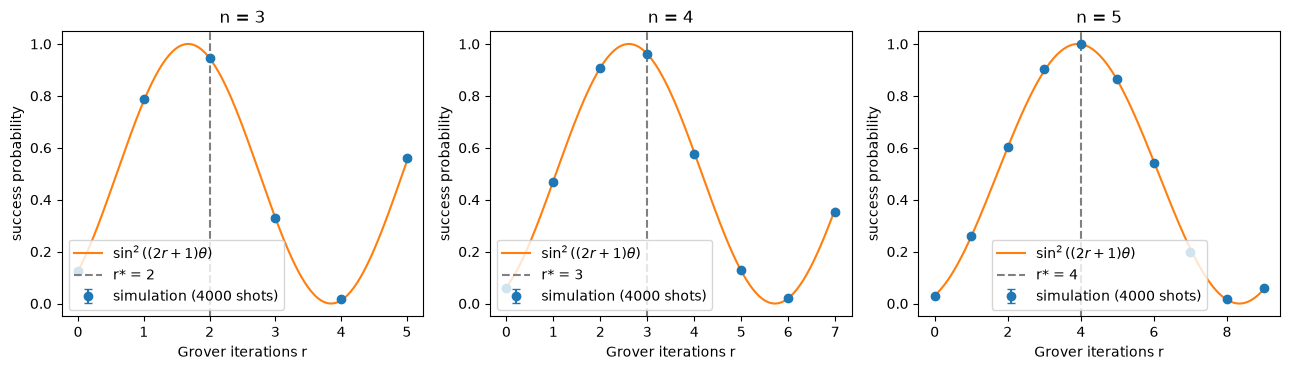

Figure 1: ideal (noise-free) success probability against r for n = 3, 4, 5. Points are simulated with 4000 shots (error bars: one standard error); the curve is sin^2((2r+1)theta). The maximum sits at r*, and further iterations rotate past the key so the probability falls again.

Two-qubit gates per Grover iteration (oracle + diffuser, official transpilation):
 n | cx gates
 2 | 2
 3 | 12
 4 | 28
 5 | 72
 6 | 164


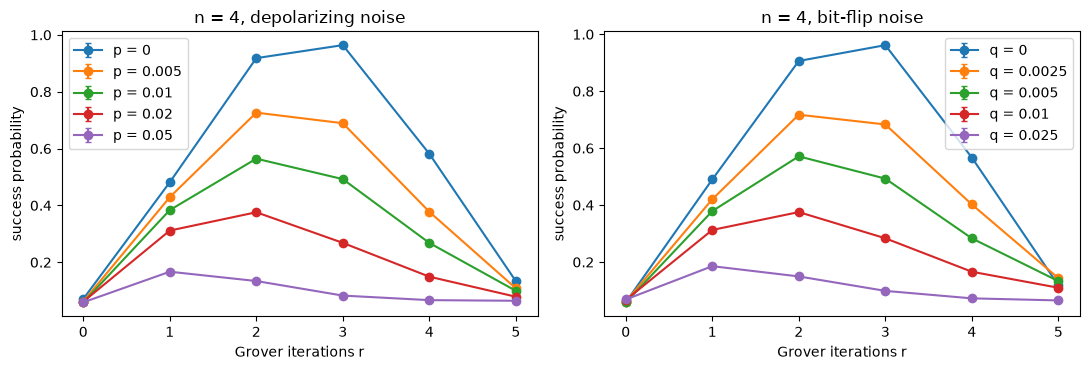

Figure 2: measured success probability against r for n = 4 under depolarizing (left) and bit-flip (right) noise; 4000 shots per point. Stronger noise lowers the peak and moves it to a smaller r.

Best measured r, its success probability and the query-matched classical baseline (r+1)/N:
 n  model         level   best r   P_best   +/- sigma   (r+1)/N   margin/sigma   Grover wins (>3 sigma)?
 3  depolarizing      0       2     0.946      0.004     0.375         159.4   yes
 3  depolarizing  0.005       2     0.858      0.006     0.375          87.5   yes
 3  depolarizing   0.01       2     0.771      0.007     0.375          59.5   yes
 3  depolarizing   0.02       2     0.651      0.008     0.375          36.7   yes
 3  depolarizing   0.05       1     0.479      0.008     0.250          29.0   yes
 3  bit-flip          0       2     0.947      0.004     0.375         160.6   yes
 3  bit-flip     0.0025       2     0.839      0.006     0.375          79.7   yes
 3  bit-flip      0.005    

In [34]:
# Participant Code: Task GRV-X1
# Experiments for Section 9.
import time
_t0 = time.time()
D_LEVELS = [0, 0.005, 0.01, 0.02, 0.05]
B_LEVELS = [0, 0.0025, 0.005, 0.01, 0.025]
MODELS = {"depolarizing": (build_depolarizing_noise_model, D_LEVELS, "p"),
          "bit-flip": (build_bitflip_noise_model, B_LEVELS, "q")}
KEYS = {n: (DEMO_KEY * 2)[:n] for n in (2, 3, 4, 5, 6)}      # fixed key per size; n = 4 is DEMO_KEY
sigma = lambda P, m: math.sqrt(max(P * (1 - P), 0.0) / m)

# 1. Ideal behaviour -----------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, n in zip(axes, (3, 4, 5)):
    r_star = optimal_iterations(n)
    rs = list(range(0, 2 * r_star + 2))
    meas = [run_noisy_grover(KEYS[n], r, None, EXPERIMENT_SHOTS, SEED + 10 * n + r) for r in rs]
    ax.errorbar(rs, meas, yerr=[sigma(P, EXPERIMENT_SHOTS) for P in meas], fmt="o", capsize=3, label="simulation (4000 shots)")
    fine = np.linspace(0, rs[-1], 200)
    theta = math.asin(math.sqrt(2.0 ** -n))
    ax.plot(fine, np.sin((2 * fine + 1) * theta) ** 2, label=r"$\sin^2((2r+1)\theta)$")
    ax.axvline(r_star, color="gray", ls="--", label=f"r* = {r_star}")
    ax.set_xlabel("Grover iterations r"); ax.set_ylabel("success probability"); ax.set_title(f"n = {n}"); ax.legend()
plt.tight_layout(); plt.show()
print("Figure 1: ideal (noise-free) success probability against r for n = 3, 4, 5. Points are simulated with "
      "4000 shots (error bars: one standard error); the curve is sin^2((2r+1)theta). The maximum sits at r*, "
      "and further iterations rotate past the key so the probability falls again.")

# 2. Resources -----------------------------------------------------------------------
print("\nTwo-qubit gates per Grover iteration (oracle + diffuser, official transpilation):")
print(" n | cx gates")
cx_counts = {}
for n in range(2, 7):
    iteration = QuantumCircuit(n)
    iteration.compose(build_oracle(KEYS[n]), inplace=True)
    iteration.compose(build_diffuser(n), inplace=True)
    cx_counts[n] = count_two_qubit_gates(official_transpile(iteration))
    print(f" {n} | {cx_counts[n]}")

# 3 + 4. Noise sweeps (data are reused for the size table) --------------------------------
data = {}     # (n, model, level) -> list of success estimates for r = 0 .. r* + 2
for n in (3, 4, 5):
    r_range = range(0, optimal_iterations(n) + 3)
    for name, (builder, levels, _) in MODELS.items():
        for li, level in enumerate(levels):
            model = builder(level)
            data[(n, name, level)] = [run_noisy_grover(KEYS[n], r, model, EXPERIMENT_SHOTS,
                                                       SEED + 1000 * n + 100 * li + 10 * (name == "bit-flip") * 50 + r)
                                      for r in r_range]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (name, (_, levels, symbol)) in zip(axes, MODELS.items()):
    for level in levels:
        vals = data[(4, name, level)]
        ax.errorbar(range(len(vals)), vals, yerr=[sigma(P, EXPERIMENT_SHOTS) for P in vals],
                    marker="o", capsize=2, label=f"{symbol} = {level}")
    ax.set_xlabel("Grover iterations r"); ax.set_ylabel("success probability"); ax.set_title(f"n = 4, {name} noise")
    ax.legend()
plt.tight_layout(); plt.show()
print("Figure 2: measured success probability against r for n = 4 under depolarizing (left) and bit-flip (right) "
      "noise; 4000 shots per point. Stronger noise lowers the peak and moves it to a smaller r.")

# 4 + 5. Size dependence and classical comparison --------------------------------------
print("\nBest measured r, its success probability and the query-matched classical baseline (r+1)/N:")
print(" n  model         level   best r   P_best   +/- sigma   (r+1)/N   margin/sigma   Grover wins (>3 sigma)?")
rows = []
for n in (3, 4, 5):
    for name, (_, levels, _) in MODELS.items():
        for level in levels:
            vals = data[(n, name, level)]
            r_best = int(np.argmax(vals)); P = vals[r_best]
            base = classical_success_probability(n, r_best); s = sigma(P, EXPERIMENT_SHOTS)
            margin = (P - base) / s if s > 0 else float("inf")
            wins = margin > 3
            rows.append((n, name, level, r_best, P, wins))
            print(f" {n}  {name:12s} {level:6}   {r_best:5d}   {P:7.3f}   {s:8.3f}   {base:7.3f}   {margin:11.1f}   {'yes' if wins else 'no'}")
print("Table: best iteration count and success probability for each size and noise level, with the verdict "
      "against the classical attacker who uses the same number of oracle queries.")
print(f"\nExperiment runtime: {time.time() - _t0:.0f} s")

**Your answer (GRV-Q1):**

The uniform state |s⟩ = sin θ |w⟩ + cos θ |w⊥⟩ lies almost along the unmarked direction |w⊥⟩, with sin²θ = 1/N. The oracle reflects the state about |w⊥⟩ (it flips the sign of the |w⟩ component) and the diffuser reflects it about |s⟩. Two reflections compose to a rotation by twice the angle between their axes, which is 2θ. Starting at angle θ from |w⊥⟩, after r iterations the state is at angle (2r+1)θ, so G^r|s⟩ = sin((2r+1)θ)|w⟩ + cos((2r+1)θ)|w⊥⟩ and P_r = sin²((2r+1)θ). The probability is largest when (2r+1)θ is closest to π/2, i.e. r* ≈ π/(4θ) − ½ (r* = 1, 2, 3, 4 for n = 2, 3, 4, 5). Beyond r* the rotation carries the state past |w⟩ and the probability falls again, reaching zero near r ≈ π/(2θ). The measured noise-free curves (Figure 1) follow sin²((2r+1)θ) within the one-standard-error bars and have their peak at r*: the best measured values were 0.946 (n = 3, r = 2), 0.964 (n = 4, r = 3) and 0.999 (n = 5, r = 4), matching the ideal 0.945, 0.961 and 0.999. After the peak the measured probability falls, as predicted.

**Your answer (GRV-Q2):**

Both noise types lower the whole curve and move the best r to smaller values (Figure 2). For n = 4 the peak success drops from 0.964 (no noise, r = 3) to 0.727, 0.565, 0.376 and 0.167 for depolarizing p = 0.005, 0.01, 0.02, 0.05, and to 0.718, 0.571, 0.376 and 0.185 for bit-flip q = 0.0025, 0.005, 0.01, 0.025. The best r falls from 3 to 2 already at p = 0.005 (q = 0.0025) and to 1 at p = 0.05 (q = 0.025). Simple model: each iteration keeps the state with fidelity F ≈ (1 − ε)^{C}, where C is the number of two-qubit gates per iteration (28 for n = 4, Table above) and ε is the error per gate, and an error turns the state into a roughly uniform one. Then P_r ≈ F^r sin²((2r+1)θ) + (1 − F^r)/N. The factor F^r decays exponentially in r while sin² grows only until r*, so the maximum of the product moves to smaller r as F decreases, and the peak height falls to a value that tends to 1/N for large r. Assumptions: independent gate errors, errors that fully scramble the state, no cancellation between errors, and the single-qubit errors are negligible compared with the cx errors. The noisy optimum need not be smaller than r* when the noise is weak or the curve is flat near r*: for n = 3 the best r stays at r* = 2 for depolarizing p up to 0.01 and bit-flip q up to 0.005 (at p = 0.02 the r = 1 and r = 2 values are nearly tied, so the best r depends on the seed), because F^r changes little over one iteration and sin² is flat there. A bit flip can also be partly harmless, e.g. an X error that lands on the target of a later X gate or is undone by the next gate, so the bit-flip model degrades slightly less than the independent-error assumption suggests.

**Your answer (GRV-Q3):**

The table shows that Grover search beats the query-matched baseline (r+1)/N by more than 3 standard errors in 28 of the 30 configurations, including all n = 3 and n = 4 cases up to p = 0.05 and q = 0.025 (for example n = 4, p = 0.05: 0.167 against 0.125 at r = 1, 7 σ). It fails only for n = 5 at the two strongest noise levels, p = 0.05 (best P = 0.037 at r = 1, baseline 0.0625) and q = 0.025 (0.045 against 0.0625). For n = 5 with p = 0.01 or q = 0.005 the advantage is already small in absolute terms: P is 0.188 and 0.179 against baselines 0.094. This follows the gate counts: one iteration needs 2, 12, 28, 72 and 164 two-qubit gates for n = 2 to 6, a growth of about a factor 2.5 per added qubit. The fidelity per iteration scales like (1 − ε)^{C}, so a given noise level that is harmless at n = 3 (C = 12) destroys the signal at n = 5 (C = 72). Since r* also grows like √N, the total number of two-qubit gates needed grows much faster than the n of the key, and the maximum tolerable error per gate shrinks accordingly; the advantage disappears when C·ε reaches about 1.

**Your answer (GRV-Q4):**

Grover's algorithm gives only a quadratic speed-up: a k-bit key needs about 2^{k/2} iterations instead of 2^k, so a 128-bit key still needs about 2^{64} sequential oracle calls, each of which is a deep circuit (our table shows two-qubit gates per iteration growing from 12 at n = 3 to 164 at n = 6, and a real cipher oracle is far larger). The iterations must run one after another, and splitting the search over k machines only gives a √k reduction in time, so parallelization is much less effective than classically. Our results show that even small gate errors destroy the advantage for n = 5 (about 72 two-qubit gates per iteration), so a real attack would need fault-tolerant, error-corrected qubits with a large overhead in physical qubits and time, and error-corrected gates are slow. Hence brute-force search against well-designed symmetric ciphers is not an imminent threat: the practical response is to use longer keys (for example 256-bit keys keep a 128-bit post-quantum security margin) rather than a drastic change. This simulation is small (n ≤ 6) and does not model a full cipher oracle or error correction, so the conclusion about large key sizes is an extrapolation, not a measured result.

## 10. Expected deliverables

1. Working implementations of `build_oracle`, `build_diffuser`, `build_grover_circuit`, `ideal_success_probability`, `optimal_iterations`, `classical_success_probability`, `build_depolarizing_noise_model`, `build_bitflip_noise_model`, `success_probability`, `run_noisy_grover` and `best_iteration_count`.
2. The experiments, table and figures of Section 9.
3. Written answers to GRV-Q1, GRV-Q2, GRV-Q3 and GRV-Q4.

The notebook must execute from top to bottom in a fresh kernel within 20 minutes on a standard laptop.

## 11. Published scoring rubric

| Criterion | Points | Assessment |
|:--|--:|:--|
| GRV-C1 Oracle correctness for hidden keys (T1) | 15 | automatic |
| GRV-C2 Diffusion operator (T2) | 10 | automatic |
| GRV-C3 Grover circuit and ideal success probability (T3) | 15 | automatic |
| GRV-C4 Ideal theory: success probability and optimal iterations (T4) | 8 | automatic |
| GRV-C5 Classical baseline (T5) | 4 | automatic |
| GRV-C6 Depolarizing noise model (T6) | 8 | automatic |
| GRV-C7 Bit-flip noise model (T7) | 8 | automatic |
| GRV-C8 Noisy success-probability estimation (T8) | 10 | automatic |
| GRV-C9 Best iteration count under a shot budget (T9) | 12 | automatic |
| GRV-C10 Experimental design, resource accounting and interpretation (Section 9, Q1 to Q4) | 10 | manual, structured review form |
| **Total** | **100** | |

The general rules on re-execution, statistical tolerances, partial credit and integrity violations stated in Challenge 1, Section 11, apply here as well. Hidden tests use keys and sizes that do not appear in this notebook; implementations that only work for the demonstration key do not receive credit.

## 12. Submission instructions

1. Restart the kernel and run all cells. Check that the run completes within the time limit.
2. Keep the file name `02_grover_search_under_noise.ipynb`.
3. Submit it in your team folder as described in `README.md`.

## 13. Scientific references

1. L. K. Grover, "A fast quantum mechanical algorithm for database search," in *Proceedings of the 28th Annual ACM Symposium on Theory of Computing*, 212 (1996). DOI: 10.1145/237814.237866
2. L. K. Grover, "Quantum mechanics helps in searching for a needle in a haystack," *Physical Review Letters* 79, 325 (1997). DOI: 10.1103/PhysRevLett.79.325
3. C. H. Bennett, E. Bernstein, G. Brassard and U. Vazirani, "Strengths and weaknesses of quantum computing," *SIAM Journal on Computing* 26, 1510 (1997). DOI: 10.1137/S0097539796300933
4. M. Boyer, G. Brassard, P. Hoyer and A. Tapp, "Tight bounds on quantum searching," *Fortschritte der Physik* 46, 493 (1998). arXiv: quant-ph/9605034
5. C. Zalka, "Grover's quantum searching algorithm is optimal," *Physical Review A* 60, 2746 (1999). DOI: 10.1103/PhysRevA.60.2746
6. A. Barenco, C. H. Bennett, R. Cleve, D. P. DiVincenzo, N. Margolus, P. Shor, T. Sleator, J. A. Smolin and H. Weinfurter, "Elementary gates for quantum computation," *Physical Review A* 52, 3457 (1995). DOI: 10.1103/PhysRevA.52.3457
7. M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, 10th anniversary edition, Cambridge University Press (2010), Chapters 6 and 8.
8. Qiskit documentation: https://quantum.cloud.ibm.com/docs/en/api/qiskit
9. Qiskit Aer noise models: https://qiskit.github.io/qiskit-aer/apidocs/aer_noise.html